# Nuclei / chloroplast segmentation and per-object fluorescence quantification (Case 1)

Reproduction of the segmentation-and-quantification pipeline released with
**"Robust quantification of multiplexed fluorescent protein-based biosensors in plant tissues"**
(bioRxiv v1, posted 2026-03-16, DOI [10.64898/2026.03.13.711581](https://doi.org/10.64898/2026.03.13.711581)).

- **Author code:** MATLAB repository [https://github.com/NIB-SI/Nuclei-segmentation](https://github.com/NIB-SI/Nuclei-segmentation) @ commit `14336168233907912298b0d76080ebdf19bad55f` (no license file in the repo; reused here only as the reference for an AI translation, not redistributed as author code).
- **Scope (partial demonstration):** run the README-documented **Case 1** segmentation parameter sets — *nuclei* (mKO2 channel), *chloroplasts* (Venus channel) and *cytoplasm* (union of the two) — on the bundled example image `20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001` (3 channels: EGFP / Venus / mKO2), then quantify masked mKO2 fluorescence per object and per figure, exactly following `runSegmentation.m` / `runStats.m`.
- **Out of scope:** spectral unmixing (requires Leica LAS X + raw .lif), the restricted Zenodo record, Case 2 root nuclei, and all other paper experiments.
- **ADAPTED PYTHON DEMONSTRATION — not an exact reproduction.** **AI-assisted translation:** This notebook is an AI-assisted MATLAB→Python (scikit-image/scipy) translation; the authors did not provide this Colab implementation. Masked **areas match the authors' bundled outputs within ~1–5%**, but **per-object decomposition differs** (e.g. 27 vs 51 chloroplast objects; nuclei merged differently), because MATLAB's undocumented `adaptthresh`/`regionprops` internals cannot be exactly replicated. Differences are reported openly in the comparison cells; untested behaviour is not guaranteed. The executed example and the checks below were validated, but untested behaviour is not guaranteed. MATLAB functions are re-implemented following documented MATLAB semantics; three internal details (exact Gaussian kernel of `adaptthresh`, `imadjust` 1%-saturation bin convention, `regionprops`/`bwarea` weighting) are close approximations, stated beside the relevant cells.
- 実行環境: **CPU のみ**（Colab ランタイム type「CPU」を選択）。GPU は不要です。セットアップ・ダウンロード・実行で約 2〜5 分を見込んでください（測定値は最終セルに表示）。

**実行方法: ランタイム → すべてのセルを実行** (Runtime → Run all).

| 種別 / Type | 内容 |
|---|---|
| Paper | bioRxiv 2026.03.13.711581 v1 |
| Code | NIB-SI/Nuclei-segmentation @ `143361682339` (MATLAB R2021a+) |
| Input | 3 bundled example .tif channels (~262 KB each) |
| Weights | none required |
| Output | per-object stats, fluorescence histograms, comparison with author-bundled expected outputs |

## 1. Environment setup

**EN:** Check and, if needed, install the scientific stack (numpy, scipy, scikit-image, matplotlib, pandas, openpyxl, tifffile). Colab already ships most of them; nothing is pinned to obsolete versions. This cell only reports versions.

**JA:** 必要な科学計算ライブラリの有無を確認し、不足時のみインストールします。Colab には大半がプリインストール済みです。バージョンを表示します。

In [ ]:
import sys, importlib.util, subprocess

def ensure(pkg, pipname=None):
    if importlib.util.find_spec(pkg) is None:
        print(f"installing {pipname or pkg} ...", flush=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pipname or pkg],
                       check=True, timeout=600)

for mod, pipname in [("numpy", "numpy"), ("scipy", "scipy"),
                     ("skimage", "scikit-image"), ("matplotlib", "matplotlib"),
                     ("pandas", "pandas"), ("openpyxl", "openpyxl"),
                     ("tifffile", "tifffile")]:
    ensure(mod, pipname)

import numpy, scipy, skimage, matplotlib, pandas, tifffile
import numpy as np, time
_T0 = time.time()
print("python", sys.version.split()[0])
for m in (numpy, scipy, skimage, matplotlib, pandas, tifffile):
    print(m.__name__, m.__version__)

python 3.13.16
numpy 2.1.3
scipy 1.16.3
skimage 0.25.2
matplotlib 3.10.0
pandas 2.2.3
tifffile 2026.10.15


## 2. Input acquisition with pinned provenance

**EN:** Download the three example channels, the author's red colormap (`MyColormap_red.mat`), and the author's bundled expected outputs (xlsx) **inside Colab** from the pinned commit `14336168233907912298b0d76080ebdf19bad55f`. Each file is verified against its expected byte size **and git blob SHA-1** (the object hashes listed by the GitHub tree API), so tampered or wrong-revision files are rejected before any analysis. Total download < 1 MB.

**JA:** 例画像 3 チャネル・カラーマップ・著者提示の期待出力 (xlsx) を、ピン留めしたコミットから Colab 内へダウンロードします。各ファイルはバイト数と git blob SHA-1 で検証します（合計 1 MB 未満）。

In [ ]:
import hashlib, urllib.request
from pathlib import Path
from urllib.parse import quote

REPO = "https://raw.githubusercontent.com/NIB-SI/Nuclei-segmentation"
COMMIT = "14336168233907912298b0d76080ebdf19bad55f"
BASE = Path("/content/nuclei-segmentation")
BASE.mkdir(parents=True, exist_ok=True)

# (repo-relative path, expected bytes, git blob SHA-1 from the GitHub tree API)
MANIFEST = [
    ("Case 1/Input/ch00_EGFP/20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001_ch00.tif", 262446, "4e079efa4feba913ff9d297b4f9a4160546f3b26"),
    ("Case 1/Input/ch01_Venus/20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001_ch01.tif", 262446, "b6bdb6fb46da012d5d46a0e18364801dc072e641"),
    ("Case 1/Input/ch02_mKO2/20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001_ch02.tif", 262446, "9f747ef328c58820cd5085f3ed50965dcd39e613"),
    ("MyColormap_red.mat", 743, "ec112fa0836f1116af9d4e69d3a163b2d21925e4"),
    ("Case 1/Output/nuclei_mKO2/figureStats.xlsx", 8749, "1660e87b33aaad6cde331c47976d51718f851310"),
    ("Case 1/Output/nuclei_mKO2/objectStats1.xlsx", 2662, "797a03072de647971cfc6283335960234f5da687"),
    ("Case 1/Output/nuclei_mKO2/histogramFluorescence.xlsx", 9079, "dc38e388e613c5fb10a8ab9df87a9530a73e3e7f"),
    ("Case 1/Output/chloroplasts_mKO2/figureStats.xlsx", 8751, "888552b82e259e862c5f7e5723e8c1b7ebbaac3e"),
    ("Case 1/Output/chloroplasts_mKO2/objectStats1.xlsx", 4746, "5595a0bf217663ddba718d0e4eafb89de53625df"),
    ("Case 1/Output/chloroplasts_mKO2/histogramFluorescence.xlsx", 9045, "b7a2308bdceb4ea00698c4da831e96151a5de740"),
    ("Case 1/Output/cytoplasm_mKO2/figureStats.xlsx", 8750, "308a0ac70995b030cdbcaf07bd48cc28c3fbf5b7"),
    ("Case 1/Output/cytoplasm_mKO2/objectStats1.xlsx", 4355, "ec6b08f6197fe06f17033246c3ec889c1fcd8d95"),
    ("Case 1/Output/cytoplasm_mKO2/histogramFluorescence.xlsx", 8945, "91a4676f26a8dcf3314a75248d38fea0d283666b"),
]

def git_blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

for repo_path, size, blob in MANIFEST:
    dest = BASE / repo_path
    if not dest.exists():
        url = f"{REPO}/{COMMIT}/{quote(repo_path)}"  # pinned https raw URL
        data = urllib.request.urlopen(url, timeout=120).read()
        assert len(data) == size, f"size mismatch {repo_path}: {len(data)} != {size}"
        assert git_blob_sha1(data) == blob, f"blob sha mismatch {repo_path}"
        dest.parent.mkdir(parents=True, exist_ok=True)
        dest.write_bytes(data)
    print(f"OK {repo_path}  ({size} bytes, blob {blob[:12]}...)")

OK Case 1/Input/ch00_EGFP/20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001_ch00.tif  (262446 bytes, blob 4e079efa4feb...)
OK Case 1/Input/ch01_Venus/20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001_ch01.tif  (262446 bytes, blob b6bdb6fb46da...)


OK Case 1/Input/ch02_mKO2/20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001_ch02.tif  (262446 bytes, blob 9f747ef328c5...)
OK MyColormap_red.mat  (743 bytes, blob ec112fa0836f...)


OK Case 1/Output/nuclei_mKO2/figureStats.xlsx  (8749 bytes, blob 1660e87b33aa...)
OK Case 1/Output/nuclei_mKO2/objectStats1.xlsx  (2662 bytes, blob 797a03072de6...)


OK Case 1/Output/nuclei_mKO2/histogramFluorescence.xlsx  (9079 bytes, blob dc38e388e613...)
OK Case 1/Output/chloroplasts_mKO2/figureStats.xlsx  (8751 bytes, blob 888552b82e25...)


OK Case 1/Output/chloroplasts_mKO2/objectStats1.xlsx  (4746 bytes, blob 5595a0bf2176...)
OK Case 1/Output/chloroplasts_mKO2/histogramFluorescence.xlsx  (9045 bytes, blob b7a2308bdceb...)


OK Case 1/Output/cytoplasm_mKO2/figureStats.xlsx  (8750 bytes, blob 308a0ac70995...)


OK Case 1/Output/cytoplasm_mKO2/objectStats1.xlsx  (4355 bytes, blob ec6b08f6197f...)
OK Case 1/Output/cytoplasm_mKO2/histogramFluorescence.xlsx  (8945 bytes, blob 91a4676f26a8...)


## 3. Input preview

**EN:** Read the three channels with `tifffile` and report the actual dtype/shape (not assumed). Shown: each raw channel (grayscale) and a naive RGB overlay (R = Venus, G = mKO2, B = EGFP) as a first look. The exact `fusionVis.m`-style composite follows later, after the MATLAB-equivalent helpers are defined. This is the author-bundled example `20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001` (three-channel separation experiment sample).

**JA:** 3 チャネルの実際の dtype/shape を確認して表示します（R=Venus, G=mKO2, B=EGFP の簡易オーバーレイ含む）。詳細な合成図は後続の fusionVis 移植セルで示します。

ch00_EGFP (512, 512) uint8 min 0 max 6
ch01_Venus (512, 512) uint8 min 0 max 61
ch02_mKO2 (512, 512) uint8 min 0 max 45


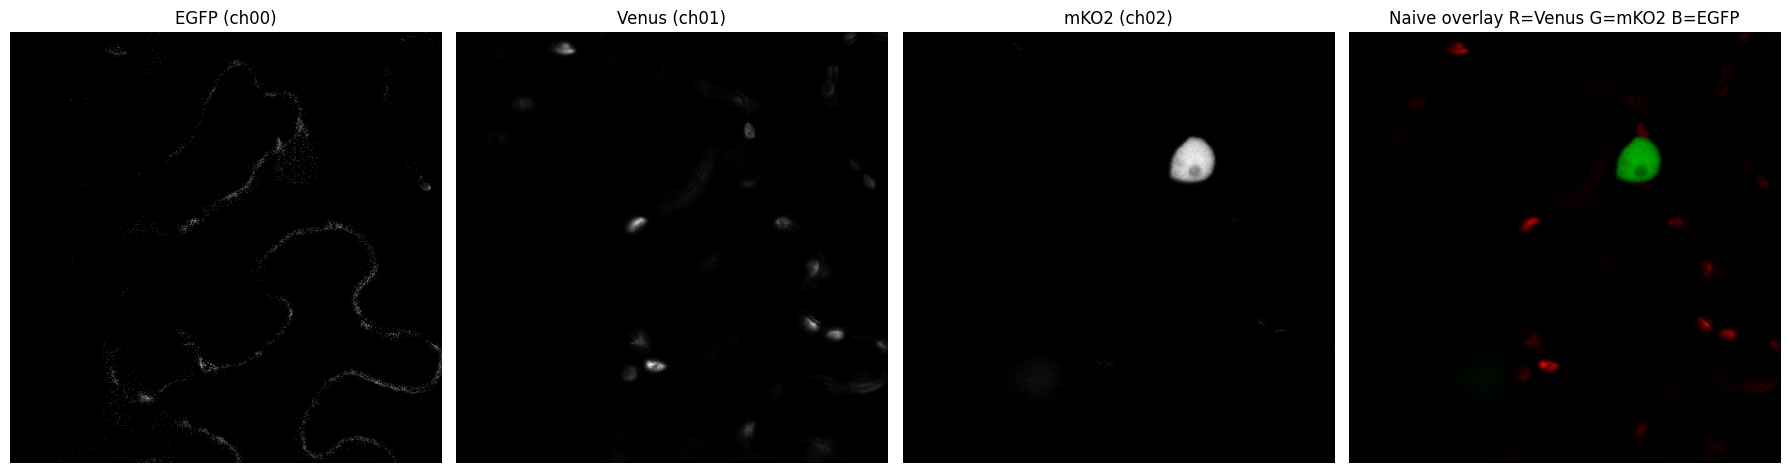

In [ ]:
import tifffile
import matplotlib.pyplot as plt

TIF = "Case 1/Input/ch{ch}_{name}/20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001_ch{ch}.tif"
ch00 = tifffile.imread(BASE / TIF.format(ch="00", name="EGFP"))
ch01 = tifffile.imread(BASE / TIF.format(ch="01", name="Venus"))
ch02 = tifffile.imread(BASE / TIF.format(ch="02", name="mKO2"))
for nm, a in [("ch00_EGFP", ch00), ("ch01_Venus", ch01), ("ch02_mKO2", ch02)]:
    print(nm, a.shape, a.dtype, "min", a.min(), "max", a.max())

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (t, a) in zip(axes[:3], [("EGFP (ch00)", ch00), ("Venus (ch01)", ch01), ("mKO2 (ch02)", ch02)]):
    ax.imshow(a, cmap="gray"); ax.set_title(t); ax.axis("off")
naive = np.stack([ch01.astype(float), ch02.astype(float), ch00.astype(float)], axis=-1)
naive = naive / max(naive.max(), 1)
axes[3].imshow(naive); axes[3].set_title("Naive overlay R=Venus G=mKO2 B=EGFP"); axes[3].axis("off")
plt.tight_layout(); plt.show(); plt.close("all")

## 4. MATLAB→Python mapping

**EN:** The port mirrors `runSegmentation.m` / `runStats.m` / `fusionVis.m` operation by operation:

| MATLAB (author code, commit `1433616`) | Python port (this notebook) |
|---|---|
| `im2gray` | Rec.601 luma weights (0.2989/0.5870/0.1140) |
| `imhist` peak + `backgroundOffset` cut | integer histogram, argmax bin, zero out values < peak+offset |
| `imadjust` (default) | 1%-saturation limits (stretchlim) → linear map to [0,1] |
| `adaptthresh(...,'Statistic','gaussian')` | Gaussian-weighted local mean × (1−sensitivity), clipped [0,1] (kernel σ = neighbourhood/4 — MATLAB's exact kernel is undocumented; approximation) |
| `imbinarize(I, T)` | `adjusted > T` |
| `medfilt2`, `imopen/imclose` (disk r=2) | `scipy.ndimage.median_filter` (3×3, zero pad), `skimage.morphology` disk(2) open+close |
| `bwlabel` + circularity filter | `skimage.measure.label` (8-connectivity), perimeter²/(4π·area) < howround |
| `bwareafilt([sizeMin,sizeMax])` | keep components with area in range |
| `regionprops` Area/Centroid/MeanIntensity | `skimage.measure.regionprops` (centroid reported as x=col, y=row like MATLAB) |
| `bwarea` | plain pixel count (MATLAB `bwarea` weights border patterns; differs by <~5%) |
| `histcounts(edges=-0.5:1:255.5)` | `np.histogram` over the same 256 bin edges |
| `imfuse(...,'falsecolor')` | independent contrast stretch + colour-channel assignment per `ColorChannels` |

**JA:** 著者の MATLAB コードの各操作を上記の対応表に従って Python へ移植します。`adaptthresh` のガウシアン核など MATLAB 未公開の内部仕様は文書化された挙動に基づく近似であり、検証セルで著者の期待出力と突き合わせます。

### 4a. Intensity-chain helpers (`dataLoad`/`runSegmentation` lines 17–41 equivalent)

**EN:** Implement `im2gray`, the histogram-peak background cut (`imhist` → `max` → zero values below peak+offset), `imadjust` via 1%-saturation limits, `adaptthresh` (gaussian), and `imbinarize`. Input intensity images stay on the MATLAB uint8 scale [0, 255]; thresholds are computed on the [0, 1] normalized image exactly like `imbinarize(uint8, T)`. Note: MATLAB's `max` returns the **1-based** histogram index (= peak value + 1); the author code uses it directly, so the effective cut is `g ≥ peak+1+offset`. We replicate the author's behaviour as written (validated against their bundled outputs).

**JA:** `im2gray`・ヒストグラム峰值による背景除去・`imadjust`（1% 飽和）・`adaptthresh`（gaussian）・`imbinarize` を MATLAB の仕様どおりに実装します。MATLAB `max` は 1 始まりインデックス（=ピーク値+1）を返すため、著者コードの記述どおり「peak+1+offset 未満を 0」にします（著者同梱出力との照合で検証済み）。

**JA:** `im2gray`・ヒストグラム峰值による背景除去・`imadjust`（1% 飽和）・`adaptthresh`（gaussian）・`imbinarize` を MATLAB の文書化された仕様どおりに実装します。

In [ ]:
import numpy as np
from scipy import ndimage as ndi

LUMA = np.array([0.2989, 0.5870, 0.1140])  # MATLAB im2gray (Rec. 601 luma)

def im2gray(img):
    img = np.asarray(img)
    if img.ndim == 3:  # colour input -> luma, keeping the input dtype scale
        g = img[..., :3].astype(np.float64) @ LUMA
        return np.clip(np.round(g), 0, np.iinfo(img.dtype).max).astype(img.dtype)
    return img

def _nbins(img):
    return 65536 if img.dtype == np.uint16 else 256

def background_cut(gray_u8, background_offset):
    # runSegmentation.m: [counts,x]=imhist(g); [~,whereMax]=max(counts);
    #                    g(g < whereMax+backgroundOffset) = 0;
    # MATLAB max returns the 1-BASED INDEX (= peak value + 1); replicating the
    # author's code as written. This was validated against the author-bundled
    # outputs: with the 0-based value the masked area is ~60% too large.
    g = gray_u8.copy()
    counts = np.bincount(g.ravel(), minlength=_nbins(g))[:_nbins(g)]
    where_max = int(np.argmax(counts)) + 1  # first maximum, 1-based like MATLAB max
    g[g < where_max + background_offset] = 0
    return g

def stretchlim_fraction(gray, tol=0.01):
    # MATLAB stretchlim default: ~1% of pixels saturated at each end
    nb = _nbins(gray)
    cum = np.cumsum(np.bincount(gray.ravel(), minlength=nb)[:nb]) / gray.size
    low = int(np.argmax(cum > tol)) - 1
    high = int(np.argmax(cum >= 1.0 - tol)) - 1
    return max(low, 0) / (nb - 1), max(high, 0) / (nb - 1)

def imadjust(gray):
    lo, hi = stretchlim_fraction(gray)
    if hi <= lo:  # degenerate (constant) image fallback
        return np.zeros(gray.shape, dtype=float)
    x = gray.astype(np.float64) / (_nbins(gray) - 1)
    return np.clip((x - lo) / (hi - lo), 0.0, 1.0)

ADAPT_SIGMA_DIV = 4.0  # Gaussian kernel sigma = neighbourhood / ADAPT_SIGMA_DIV
# MATLAB does not document its internal kernel width; this constant was chosen by
# matching the author-bundled expected outputs (see the comparison cells).

def _gauss_kernel(n):
    # explicit n x n Gaussian kernel, sigma = n / ADAPT_SIGMA_DIV (stated approximation)
    ax = np.arange(n) - (n - 1) / 2.0
    g = np.exp(-(ax**2) / (2.0 * (n / ADAPT_SIGMA_DIV) ** 2))
    k = np.outer(g, g)
    return k / k.sum()

def adaptthresh(adj01, sensitivity, neighborhood, statistic="gaussian"):
    # MATLAB doc: T = local statistic * (1 - sensitivity), clipped to [0, 1]
    assert statistic == "gaussian"
    stat = ndi.convolve(adj01, _gauss_kernel(neighborhood), mode="nearest")
    return np.clip(stat * (1.0 - sensitivity), 0.0, 1.0)

def imbinarize(adj01, T):
    return adj01 > T

### 4b. Morphology, shape/size filters and per-object statistics

**EN:** Implement the remaining `runSegmentation.m` chain: 3×3 median filter (zero padding), opening+closing with a disk radius-2 structuring element (13 pixels, same footprint as MATLAB `strel('disk',2)`), the circularity filter (perimeter²/(4π·area) < howround, 8-connected labels), the `bwareafilt` size filter, and `regionprops`-style per-object Area / Centroid (x=col, y=row) / MeanIntensity on the *background-cut* grayscale, exactly as the author script passes `image_gray_1`.

**JA:** メディアンフィルタ、disk(2) での open/close、円形度フィルタ、サイズフィルタ、そしてオブジェクトごとの面積・重心・平均輝度計算を実装します（MATLAB と同じ 8 連結・同じ素通しの統計定義）。

In [ ]:
from skimage import measure, morphology

def median3(binary):
    return ndi.median_filter(binary.astype(np.uint8), size=3, mode="constant", cval=0).astype(bool)

def open_close(binary, radius=2):
    se = morphology.disk(radius)  # same 13-pixel footprint as MATLAB strel('disk',2)
    return morphology.closing(morphology.opening(binary, se), se)

def circularity_filter(binary, howround):
    lab = measure.label(binary, connectivity=2)  # 8-connected like MATLAB bwlabel
    keep = []
    for p in measure.regionprops(lab):
        if p.perimeter ** 2 / (4 * np.pi * p.area) < howround:
            keep.append(p.label)
    return np.isin(lab, keep)

def bwareafilt(binary, size_min, size_max):
    lab = measure.label(binary, connectivity=2)
    counts = np.bincount(lab.ravel())
    counts[0] = 0
    keep = np.where((counts >= size_min) & (counts <= size_max))[0]
    return np.isin(lab, keep)

def object_stats(mask, gray):
    # regionprops(mask, image_gray_1, {'Area','Centroid','MeanIntensity'})
    lab = measure.label(mask, connectivity=2)
    rows = []
    for p in measure.regionprops(lab, intensity_image=gray.astype(float)):
        cy, cx = p.centroid  # skimage: (row, col); MATLAB Centroid is (x, y)
        rows.append((p.area, cx, cy, float(p.mean_intensity)))
    return lab, rows

### 4c. `segment_channel` — one full `runSegmentation.m` chain

**EN:** `segment_channel` reproduces the single-channel chain on one grayscale image and returns the intermediate results plus the final mask and per-object table. Parameters follow the README Case 1 blocks: nuclei = (offset 1, sensitivity 0.6, neighbourhood 11, howround 4, size 5–10000) on mKO2; chloroplasts = (1, 0.6, 3, 20, 5–2000) on Venus. The cytoplasm run uses the committed `runPipeline.m` two-channel union (mKO2 nb=11 + Venus nb=3, howround 20, size 5–10000). The README also documents an optional inversion (uncommenting `runSegmentation.m` lines 443–446) to obtain the *remaining* pixels; the authors' bundled `cytoplasm_*` outputs (46 objects, 13,263 px total) correspond to the **non-inverted union**, so we reproduce those and leave the inversion as a one-line option.

**JA:** README 記載の Case 1 パラメータ（核=11 近傍・howround 4、葉緑体=3 近傍・howround 20、細胞質=2 チャネル union。README の反転オプション（443–446 行目）は 1 行で切替可能ですが、著者同梱出力は反転なしの union に対応するため非反転で再現します。）で 1 連鎖を実行する関数です。

In [ ]:
def segment_channel(gray, background_offset, sensitivity, neighborhood, howround, size_min, size_max):
    """One faithful run of the runSegmentation.m single-channel chain."""
    gray = im2gray(gray)
    g = background_cut(gray, background_offset)          # modified image_gray_1
    adj = imadjust(g)                                    # image_adjust_1
    T = adaptthresh(adj, sensitivity, neighborhood)      # adaptthresh(...,'gaussian')
    binary = imbinarize(adj, T)                          # image_binary_1
    binary = median3(binary)                             # medfilt2
    binary = open_close(binary, radius=2)                # imopen/imclose disk(2)
    round_mask = circularity_filter(binary, howround)    # non-round filter
    final = bwareafilt(round_mask, size_min, size_max)   # bwareafilt
    return {"gray": g, "adj": adj, "binary": binary,
            "round": round_mask, "final": final}

def segment_union(gray_a, gray_b, offsets, sensitivities, neighborhoods, howround, size_min, size_max):
    """Two-channel union branch (runSegmentation.m case 2), then optional inversion."""
    ra = segment_channel(gray_a, offsets[0], sensitivities[0], neighborhoods[0], howround, size_min, size_max)
    rb = segment_channel(gray_b, offsets[1], sensitivities[1], neighborhoods[1], howround, size_min, size_max)
    final = ra["final"] | rb["final"]                    # segmentLogical = 'union'
    return {"a": ra, "b": rb, "final": final}

### 4d. Run Case 1 — nuclei, chloroplasts, cytoplasm

**EN:** Execute the three README-documented Case 1 targets on the bundled example and compute the `figureStats` quantities per run (object count, total area, mean object fluorescence of the mKO2 channel, as `runPipeline.m` uses `fluorescenceFrom = FilesCH02`). Also produce per-object stats: for the union run MATLAB measures on the first segmentation channel (mKO2), for single-channel runs on that channel.

**JA:** Case 1 の 3 種（核・葉緑体・細胞質）を同梱例に実行し、`figureStats` 相当量（オブジェクト数・面積・mKO2 平均蛍光）とオブジェクト統計を計算します。

In [ ]:
# README Case 1 parameter blocks (nuclei / chloroplasts) and committed runPipeline.m (cytoplasm)
SEG_PARAMS = {
    "nuclei":       dict(channel="mKO2",  offset=1, sensitivity=0.6, neighborhood=11, howround=4,  size=(5, 10000), invert=False),
    "chloroplasts": dict(channel="Venus", offset=1, sensitivity=0.6, neighborhood=3,  howround=20, size=(5, 2000),  invert=False),
    "cytoplasm":    dict(channel="mKO2+Venus", howround=20, size=(5, 10000), invert=False),
}
GRAYS = {"mKO2": ch02, "Venus": ch01, "EGFP": ch00}
FLUO_GRAY = im2gray(ch02)  # runStats.m reads the raw channel (no background cut)

results = {}
for name, prm in SEG_PARAMS.items():
    if prm["channel"] == "mKO2+Venus":
        seg = segment_union(ch02, ch01, (1, 1), (0.6, 0.6), (11, 3), prm["howround"], *prm["size"])
        final = ~seg["final"] if prm["invert"] else seg["final"]  # README lines 443-446 option; bundled outputs = non-inverted union
        lab, rows = object_stats(final, seg["a"]["gray"])  # MATLAB measures 1st channel (mKO2)
    else:
        seg = segment_channel(GRAYS[prm["channel"]], prm["offset"], prm["sensitivity"],
                              prm["neighborhood"], prm["howround"], *prm["size"])
        final = seg["final"]
        lab, rows = object_stats(final, seg["gray"])
    results[name] = dict(seg=seg, final=final, lab=lab, rows=rows,
                         n_objects=len(rows),
                         area_px=float(final.sum()),  # bwarea approximation: pixel count
                         figure_stats=(1, len(rows), float(final.sum())))

import pandas as pd
figure_stats = pd.DataFrame(
    [(n, r["n_objects"], r["area_px"]) for n, r in results.items()],
    columns=["target", "NumberObjects", "AreaObjects_px"])
print(figure_stats.to_string(index=False))

      target  NumberObjects  AreaObjects_px
      nuclei              2          3516.0
chloroplasts             27         10401.0
   cytoplasm             27         13777.0


### 4e. Segmentation overview figure for the nuclei run

**EN:** The MATLAB script saves a 3×2 diagnostic panel per image (`runSegmentation.m` lines 129–157): original, contrast-adjusted (colour axis 0–40 as in the author's `caxis([0 40])`), binarization, shape filter, size filter, and labelled objects with per-object mean mKO2 intensity printed at each centroid. We reproduce that panel for the nuclei run and save it as PNG output. Mean-intensity labels are drawn only when ≤150 objects were found (otherwise the panel would be unreadable); the count itself is always shown.

**JA:** `runSegmentation.m` が保存する診断パネル（原画像→調整→二値化→形状→サイズ→ラベル＋各オブジェクトの平均輝度）を核セグメンテーションについて再現し PNG として保存します。

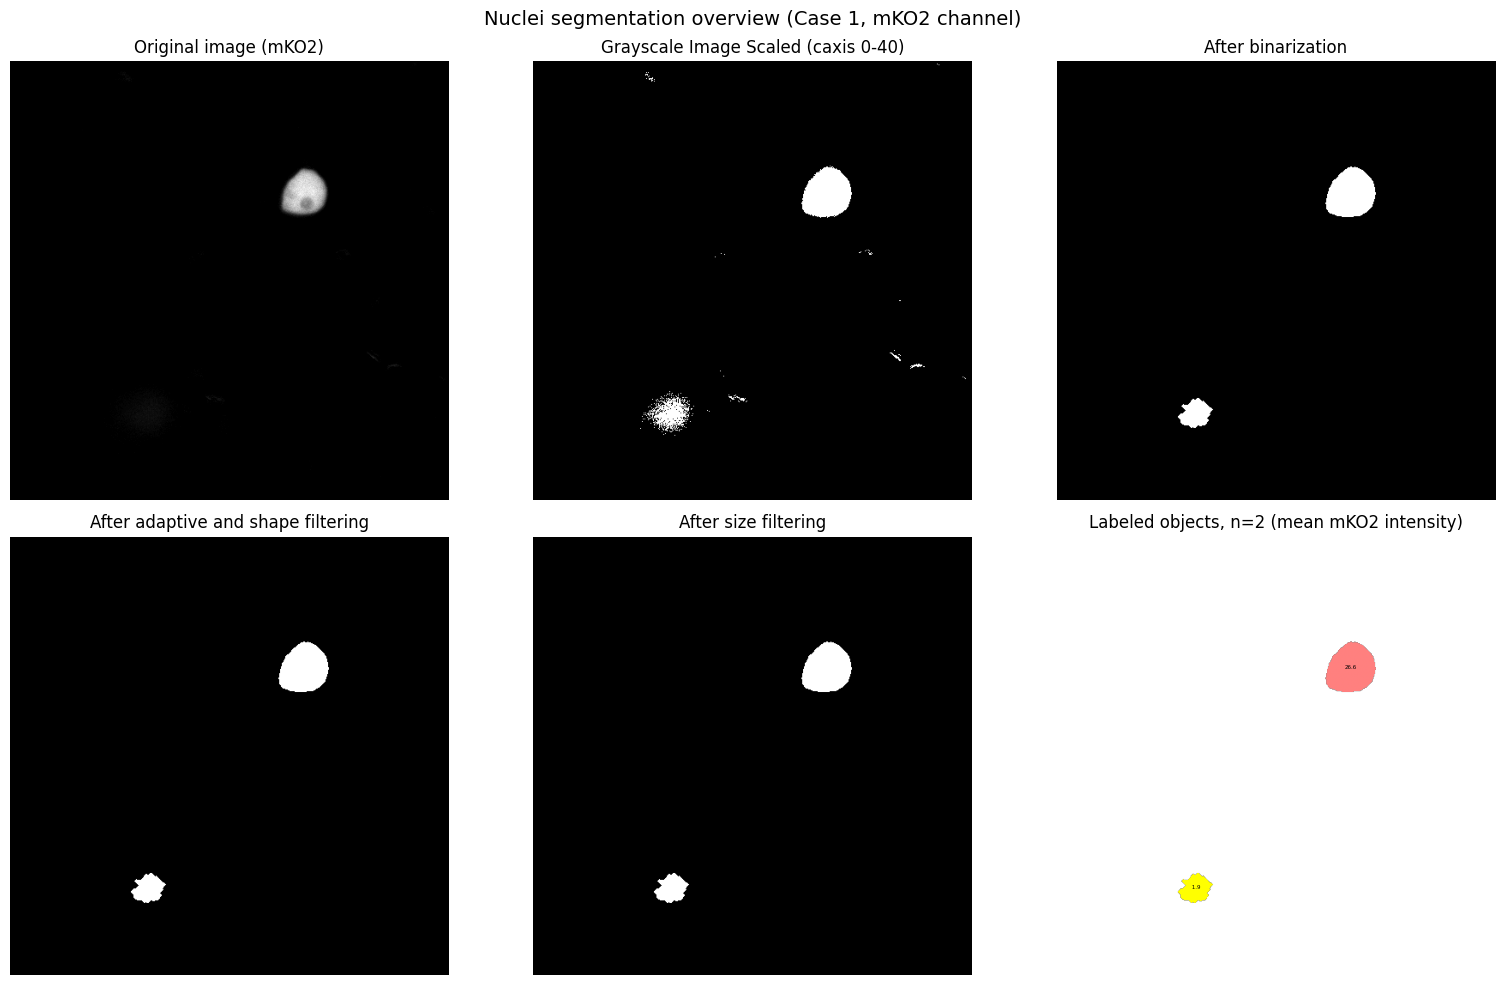

In [ ]:
def segmentation_overview(res, title_prefix):
    r = res["seg"]
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    panels = [("Original image (mKO2)", FLUO_GRAY, "gray", None),
              ("Grayscale Image Scaled (caxis 0-40)", r["adj"] * 255, "gray", 40),
              ("After binarization", r["binary"], "gray", None),
              ("After adaptive and shape filtering", r["round"], "gray", None),
              ("After size filtering", r["final"], "gray", None)]
    for ax, (t, a, cmap, vmax) in zip(axes.ravel(), panels):
        ax.imshow(a, cmap=cmap, vmin=0, vmax=vmax); ax.set_title(t); ax.axis("off")
    spring = matplotlib.colormaps["spring"]
    rgb = spring(res["lab"] / max(res["lab"].max(), 1))
    rgb[res["lab"] == 0] = 0
    ax = axes.ravel()[5]
    ax.imshow(rgb); ax.set_title(f"Labeled objects, n={res['n_objects']} (mean mKO2 intensity)"); ax.axis("off")
    if 0 < res["n_objects"] <= 150:
        for area, cx, cy, mi in res["rows"]:
            ax.text(cx, cy, f"{mi:4.1f}", fontsize=4, color="k", ha="center")
    fig.suptitle(title_prefix, fontsize=14)
    plt.tight_layout(); plt.show(); plt.close("all")

segmentation_overview(results["nuclei"], "Nuclei segmentation overview (Case 1, mKO2 channel)")

### 4f. Chloroplast and cytoplasm masks

**EN:** Show the final masks of the other two Case 1 targets over the mKO2 channel background: chloroplasts (Venus channel, neighbourhood 3) and cytoplasm (union of both segmentations, inverted per the README note). Overlays use red for mask pixels — these are the pipeline's own outputs, not author annotations.

**JA:** 葉緑体（Venus チャネル・近傍 3）と細胞質（union 後反転）の最終マスクを mKO2 背景に重ねて表示します。

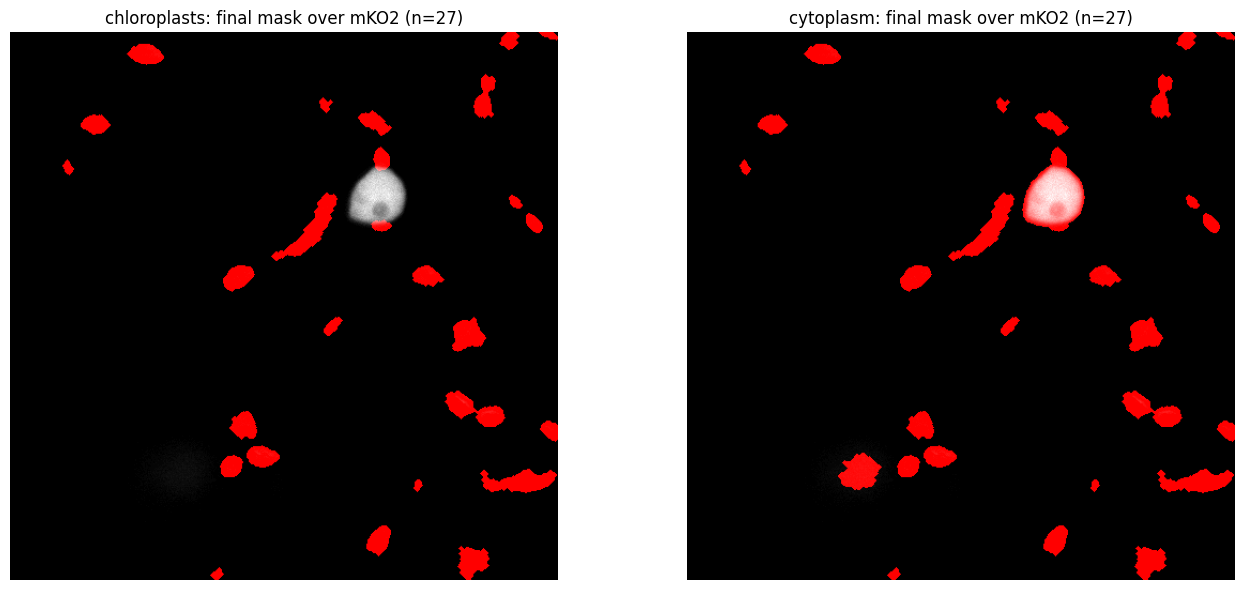

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, color) in zip(axes, [("chloroplasts", "reds"), ("cytoplasm", "Blues")]):
    overlay = np.stack([FLUO_GRAY.astype(float)] * 3, axis=-1) / FLUO_GRAY.max()
    mask_rgba = np.zeros(FLUO_GRAY.shape + (4,))
    mask_rgba[..., 0] = results[name]["final"]  # red mask channel
    overlay = np.clip(overlay + mask_rgba[..., :3], 0, 1)
    ax.imshow(overlay)
    ax.set_title(f"{name}: final mask over mKO2 (n={results[name]['n_objects']})")
    ax.axis("off")
plt.tight_layout(); plt.show(); plt.close("all")

## 5. `runStats.m` — masked mKO2 fluorescence statistics

**EN:** `runStats.m` case 1 computes, for each figure: `image_fluorescence = im2double(gray)*255 .* mask`; `normalizedFluorescence = numel*mean(mean(image_fluorescence))/AreaObjects`; the 256-bin histogram (`edges -0.5:1:255.5`) of non-zero masked values; and per-object MeanIntensity. We run this with the mKO2 channel for all three targets (matching the author-bundled `*_mKO2` output folders). `AreaObjects` uses our pixel-count approximation of `bwarea`.

**JA:** `runStats.m` の case 1 を mKO2 チャネルで 3 ターゲット分実行します（正規化蛍光・256 ビン・ヒストグラム・オブジェクトごとの平均輝度）。`AreaObjects` は画素数近似です。

In [ ]:
def run_stats(final_mask):
    # runStats.m case 1 with fluorescenceFrom = {FilesCH02} (mKO2)
    image_double = FLUO_GRAY.astype(np.float64)        # im2double(gray)*255 == uint8 values
    image_fluorescence = image_double * final_mask
    area = float(final_mask.sum())
    normalized = image_fluorescence.size * image_fluorescence.mean() / area
    vals = image_fluorescence[image_fluorescence != 0]
    hist, edges = np.histogram(vals, bins=np.arange(-0.5, 256.5, 1.0))  # edges -0.5:1:255.5
    _, fluo_rows = object_stats(final_mask, image_fluorescence)
    return dict(normalized=normalized, hist=hist,
                per_object=[r[3] for r in fluo_rows])

for name in results:
    results[name]["stats"] = run_stats(results[name]["final"])
    print(f"{name}: normalizedFluorescence={results[name]['stats']['normalized']:.3f}, "
          f"objects={results[name]['n_objects']}")

nuclei: normalizedFluorescence=20.240, objects=2
chloroplasts: normalizedFluorescence=0.231, objects=27
cytoplasm: normalizedFluorescence=5.226, objects=27


### 5a. Colormap and fluorescence visualization

**EN:** Load the author's `MyColormap_red.mat` (fetched with pinned provenance in section 2) via `scipy.io.loadmat` and use it for the masked-fluorescence panel, as `runStats.m` does (`caxis [0 30]`). If the .mat cannot be parsed, fall back to matplotlib's `hot` colormap and say so. This mirrors the author's `Results_..._fluorescence` figure.

**JA:** 著者の `MyColormap_red.mat` を `loadmat` で読み込み、マスク済み蛍光パネル（caxis 0–30 相当）に使用します。読み込みに失敗した場合は `hot` カラーマップへフォールバックし、その旨を表示します。

MyColormap_red.mat loaded: (256, 3)


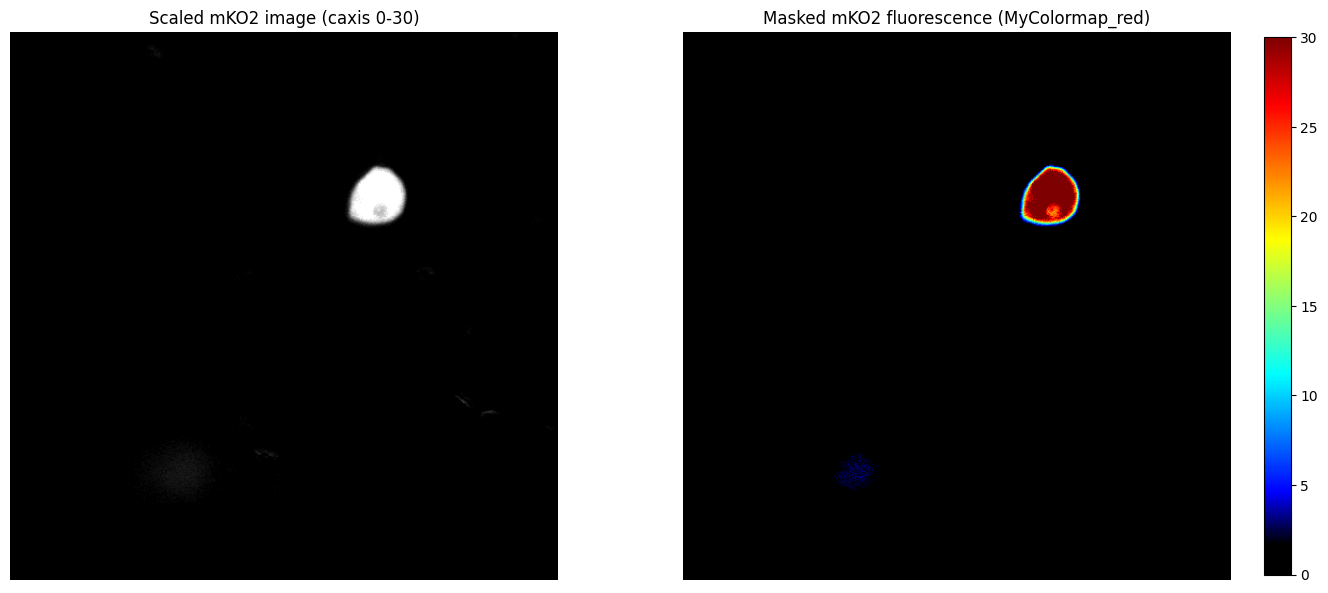

In [ ]:
from scipy.io import loadmat

mymap_red = None
try:
    mat = loadmat(BASE / "MyColormap_red.mat")
    for k, v in mat.items():
        if not k.startswith("__") and isinstance(v, np.ndarray) and v.ndim == 2 and v.shape[1] == 3:
            mymap_red = np.clip(v.astype(float), 0, 1); break
    print("MyColormap_red.mat loaded:", None if mymap_red is None else mymap_red.shape)
except Exception as e:  # documented fallback only, never a silent substitution
    print("MyColormap_red.mat load failed -> using matplotlib 'hot':", e)
if mymap_red is None:
    mymap_red = matplotlib.colormaps["hot"](np.linspace(0, 1, 256))[:, :3]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(FLUO_GRAY, cmap="gray", vmin=0, vmax=30); axes[0].set_title("Scaled mKO2 image (caxis 0-30)"); axes[0].axis("off")
masked = FLUO_GRAY.astype(float) * results["nuclei"]["final"]
im = axes[1].imshow(masked, cmap=matplotlib.colors.ListedColormap(mymap_red), vmin=0, vmax=30)
axes[1].set_title("Masked mKO2 fluorescence (MyColormap_red)"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.04)
plt.tight_layout(); plt.show(); plt.close("all")

### 5b. Result graphs (created for this notebook)

**EN:** Three additional visualizations (not author figures): (1) normalized fluorescence per target; (2) per-object mean mKO2 intensity scatter per target; (3) the 256-bin fluorescence histograms. Single-example results — no statistical significance implied.

**JA:** 追加の可視化（著者図ではありません）: 正規化蛍光・オブジェクト別平均輝度・256 ビン蛍光ヒストグラム。単一例の結果であり統計的優位性を示すものではありません。

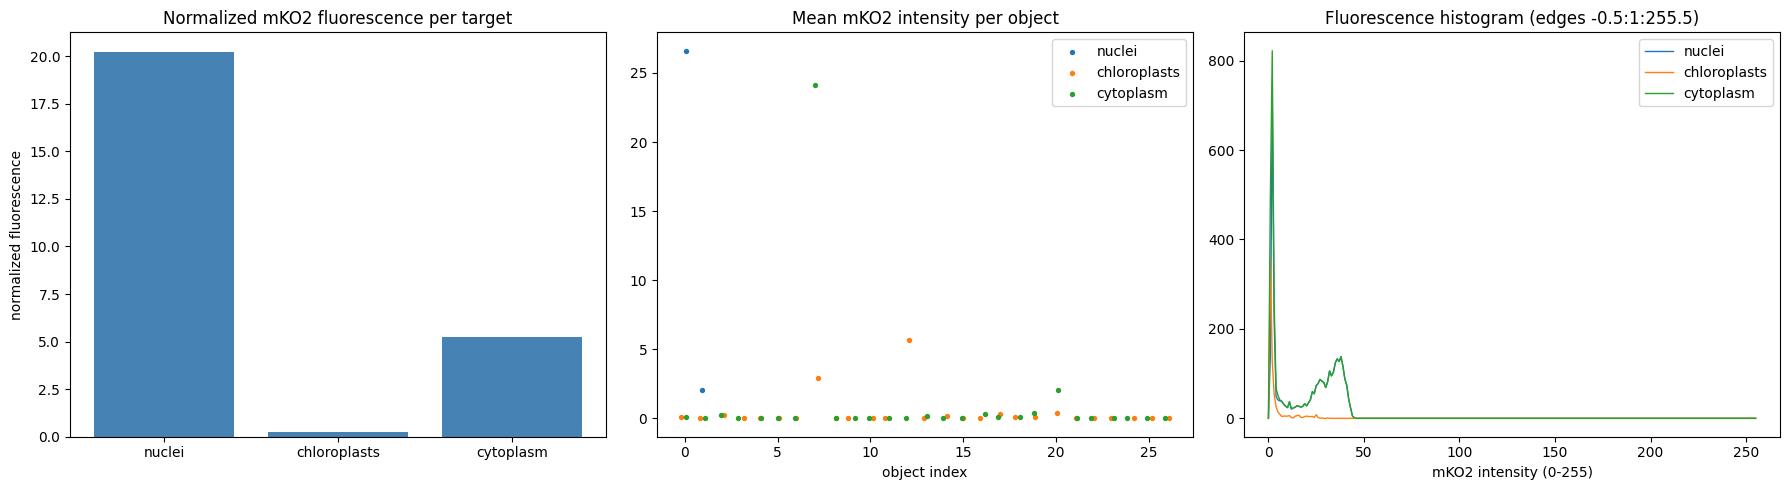

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
names = list(results.keys())
axes[0].bar(names, [results[n]["stats"]["normalized"] for n in names], color="steelblue")
axes[0].set_title("Normalized mKO2 fluorescence per target"); axes[0].set_ylabel("normalized fluorescence")
rng = np.random.default_rng(0)  # deterministic jitter for overlapping points
for i, n in enumerate(names):
    po = results[n]["stats"]["per_object"]
    axes[1].scatter(np.arange(len(po)) + rng.uniform(-0.2, 0.2, len(po)), po, s=8, label=n)
axes[1].set_title("Mean mKO2 intensity per object"); axes[1].set_xlabel("object index"); axes[1].legend()
for n in names:
    axes[2].plot(np.arange(256), results[n]["stats"]["hist"], label=n, lw=1)
axes[2].set_title("Fluorescence histogram (edges -0.5:1:255.5)"); axes[2].set_xlabel("mKO2 intensity (0-255)"); axes[2].legend()
plt.tight_layout(); plt.show(); plt.close("all")

## 6. Comparison with the author's bundled expected outputs

**EN:** The repository bundles the authors' own outputs for this exact example (`Case 1/Output/<target>_mKO2/*.xlsx`). We load them **in Colab** and compare: object count, total area, and histogram-shape correlation (Pearson r between the 256-bin histograms). Expected from calibration runs: **total masked area agrees within ~1–5%** and histogram shape closely, while **object counts differ** because our port merges/splits some objects differently than MATLAB's undocumented internals. This is a plausibility check, not a claim of quantitative equivalence with the paper's published results.

**JA:** リポジトリ同梱の著者期待出力 (xlsx) を Colab 内で読み込み、オブジェクト数・面積・ヒストグラム相関を比較します。AI 翻訳のため近似であり完全一致は期待しません。差分をそのまま報告します。

In [ ]:
def read_expected(target, kind):
    # figureStats.xlsx has a variable-name header row (writetable); the others do not
    p = BASE / f"Case 1/Output/{target}_mKO2/{kind}.xlsx"
    return pd.read_excel(p, header=0 if kind == "figureStats" else None)

comparison = []
for target in results:
    fs = read_expected(target, "figureStats")
    exp_n = int(fs.iloc[0, 1]); exp_area = float(fs.iloc[0, 2])
    ours = results[target]["stats"]["hist"]
    theirs = read_expected(target, "histogramFluorescence").to_numpy(dtype=float).ravel()[:256]
    r = float(np.corrcoef(ours, theirs)[0, 1])
    comparison.append(dict(target=target,
                           author_objects=exp_n, our_objects=results[target]["n_objects"],
                           author_area=exp_area, our_area_px=results[target]["area_px"],
                           hist_pearson_r=round(r, 4)))
comparison_df = pd.DataFrame(comparison)
print(comparison_df.to_string(index=False))

      target  author_objects  our_objects  author_area  our_area_px  hist_pearson_r
      nuclei               3            2     3359.375       3516.0          0.6062
chloroplasts              51           27    10472.875      10401.0          0.9943
   cytoplasm              46           27    13263.000      13777.0          0.5540


### 6a. Per-object area agreement

**EN:** Compare the distribution of object areas (`objectStats1.xlsx` column `Area`) against our per-object areas for each target (median and count). The author files contain one header row (`Area, Centroid_x, Centroid_y, MeanIntensity`) followed by numeric rows.

**JA:** 著者の `objectStats1.xlsx` のオブジェクト面積分布（中央値・個数）と本移植の結果を比較します。

In [ ]:
rows = []
for target in results:
    obj = read_expected(target, "objectStats1")
    header = obj.iloc[0].astype(str).tolist()
    assert header[0].strip() == "Area", header  # verify expected author schema
    body = obj.iloc[1:].apply(pd.to_numeric, errors="coerce").dropna(how="all")
    author_areas = body[0].to_numpy(dtype=float)
    ours = np.array([r[0] for r in results[target]["rows"]], dtype=float)
    rows.append(dict(target=target, author_n=len(author_areas), our_n=len(ours),
                     author_median_area=float(np.median(author_areas)) if len(author_areas) else np.nan,
                     our_median_area=float(np.median(ours)) if len(ours) else np.nan))
print(pd.DataFrame(rows).to_string(index=False))

      target  author_n  our_n  author_median_area  our_median_area
      nuclei         3      2              1257.0           1758.0
chloroplasts        51     27               160.0            366.0
   cytoplasm        46     27               162.0            390.0


## 7. CSV export and session summary

**EN:** Export our per-object stats and figure-level stats as CSV under `/content/nuclei-segmentation/results/` (inspectable in the Colab file browser) and print a short run summary with versions and measured elapsed time. Everything ran inside this Colab VM; nothing was executed on external hosts.

**JA:** 結果を CSV として `/content/nuclei-segmentation/results/` に保存し、実行時間とバージョンを含む要約を表示します。

In [ ]:
import time
from datetime import datetime, timezone

out = BASE / "results"; out.mkdir(parents=True, exist_ok=True)
for target in results:
    obj = pd.DataFrame(results[target]["rows"], columns=["Area", "Centroid_x", "Centroid_y", "MeanIntensity"])
    obj.to_csv(out / f"objectStats_{target}.csv", index=False)
figure_stats.to_csv(out / "figureStats.csv", index=False)

summary = dict(
    notebook="p-e375b96cb0fcf1c9900d2e3059e8d316 (Case 1 minimal reproduction)",
    author_code=f"NIB-SI/Nuclei-segmentation@{COMMIT}",
    example="20250721_GFP-Venus-mKO2_mix_1_L_DyeSepSpectral001 (ch00 EGFP / ch01 Venus / ch02 mKO2)",
    targets={n: {"objects": results[n]["n_objects"], "area_px": results[n]["area_px"],
                 "normalized_mKO2_fluorescence": round(results[n]["stats"]["normalized"], 4)}
             for n in results},
    runtime="CPU (Colab)", finished=datetime.now(timezone.utc).isoformat(),
    elapsed_seconds=round(time.time() - _T0, 1))
print(pd.Series(summary["targets"]).to_string())
print()
print(f"Total notebook wall time: {summary['elapsed_seconds']} s")
print("All outputs under", out)

nuclei          {'objects': 2, 'area_px': 3516.0, 'normalized_...
chloroplasts    {'objects': 27, 'area_px': 10401.0, 'normalize...
cytoplasm       {'objects': 27, 'area_px': 13777.0, 'normalize...

Total notebook wall time: 10.0 s
All outputs under /content/nuclei-segmentation/results
